# Transverse shear stresses

The first-order shear deformation theory (FSDT) gives constant transverse
shear strains through the thickness, whereas the stresses that satisfy
equilibrium vanish at the faces and vary from ply to ply. This example
computes those stresses with `Laminate.calc_transverse_shear_stress`, for
given shear forces $Q_y$, $Q_x$, and with
`Laminate.calc_aposteriori_energy`, from the strain gradients of an FSDT
solution, and verifies them against the equilibrium conditions, the
definition of `Ats` and the closed form of a homogeneous plate. SI units are
used throughout, except in the homogeneous plate, given in N and mm.

## Theory

The distribution is that of the equilibrium approach of Rohwer [1], see
[Transverse shear stresses](../transverse_shear_stresses.rst), the same that
defines `Ats` for `shear_correction='rohwer'`, see
[Shear correction](../shear_correction.rst). In two cylindrical bending
states with constant membrane forces, one with $M_{xx,x} = Q_x$,
$M_{xy,x} = Q_y$ and one with $M_{yy,y} = Q_y$, $M_{xy,y} = Q_x$, the in-plane
stresses of the plies follow from the inverse of the `ABD` matrix, and the
equilibrium equations $\tau_{xz,z} = -\sigma_{xx,x}$ and
$\tau_{yz,z} = -\sigma_{yy,y}$, integrated from the bottom face, give

$$
\begin{Bmatrix} \tau_{yz} \\ \tau_{xz} \end{Bmatrix} =
f^{(k)}(z) \begin{Bmatrix} Q_y \\ Q_x \end{Bmatrix}, \qquad
A_{ts} = \left[ \sum_k \int_{z_k}^{z_{k+1}} f^{(k)T}
\left(C_s^{(k)}\right)^{-1} f^{(k)} \, dz \right]^{-1}
$$

with $f^{(k)}(z)$ quadratic within each ply and continuous at the interfaces.
Hence the stresses vanish at both faces, integrate to the shear forces, and
their complementary energy is $Q^T A_{ts}^{-1} Q / 2$.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

from composites import laminated_plate, isotropic_plate

def print_table(rows):
    """Print each result, its reference value and their relative difference

    ``rows`` holds ``(name, value, reference)`` or ``(name, value, reference,
    scale)``; the difference is divided by ``scale``, by default the absolute
    value of the reference, e.g. the largest term of the matrix when the
    reference is zero.
    """
    print('%-36s %14s %14s %10s' % ('quantity', 'composites', 'reference',
                                    'rel. diff.'))
    for row in rows:
        name, value, ref = row[:3]
        scale = row[3] if len(row) > 3 else abs(ref)
        print('%-36s % 14.6e % 14.6e %10.1e' % (name, value, ref,
                                               abs(value - ref)/scale))

## A cross-ply laminate under $Q_x$

The $[0/90/0]$ CFRP plate, plies of 0.5 mm, under the shear force $Q_x$
alone. The plies at 0 and 90 degrees have no coupling terms $q_{16L}$,
$q_{26L}$, $q_{45L}$ in the laminate axes, so $Q_x$ produces no $\tau_{yz}$.
The stress changes slope at the interfaces, where the in-plane stiffness
changes.

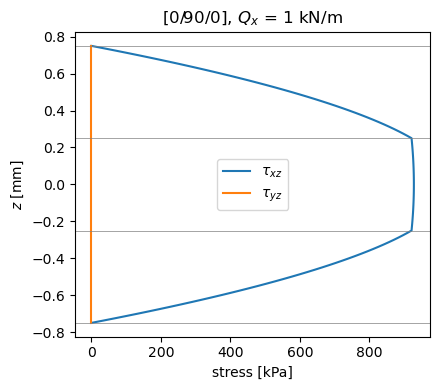

In [2]:
laminaprop = (142e9, 8.7e9, 0.28, 5.1e9, 5.1e9, 3.2e9)
lam = laminated_plate([0, 90, 0], plyt=0.5e-3, laminaprop=laminaprop)
h = lam.h
Qy, Qx = 0., 1e3 # N/m
zs = np.linspace(-h/2, h/2, 121)
tau = np.array([lam.calc_transverse_shear_stress(z, Qy, Qx) for z in zs])
tau_yz, tau_xz = tau[:, 0], tau[:, 1]

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.plot(tau_xz/1e3, zs*1e3, label=r'$\tau_{xz}$')
ax.plot(tau_yz/1e3, zs*1e3, label=r'$\tau_{yz}$')
for zi in (-h/2, -h/6, h/6, h/2):
    ax.axhline(zi*1e3, color='gray', lw=0.5)
ax.set_xlabel('stress [kPa]')
ax.set_ylabel('$z$ [mm]')
ax.set_title('[0/90/0], $Q_x$ = 1 kN/m')
ax.legend()
fig.tight_layout()
plt.show()

## Verification: faces, resultants and energy

The resultants $\int \{\tau_{yz}, \tau_{xz}\} dz$ and the complementary
energy $\int \tau^T (C_s^{(k)})^{-1} \tau \, dz / 2$ are integrated with the
3-point Gauss-Legendre rule per ply, exact for the integrands, of degree 2
and 4 in $z$, so they agree with $Q$ and $Q^T A_{ts}^{-1} Q / 2$ to
round-off. The factor `scf_k13 = A55/Abar55` is below one: the
constant-strain stiffness $\bar{A}_{ts}$ overestimates the transverse shear
stiffness of the laminate.

In [3]:
Q = np.array([Qy, Qx])
xi, w = np.polynomial.legendre.leggauss(3)
zk = -h/2
resultant = np.zeros(2)
Ustar = 0.
for ply in lam.plies:
    Cs = np.asarray(ply.get_constitutive_matrix())[3:, 3:]
    for x, wi in zip(xi, w):
        z = zk + ply.h*(x + 1)/2
        t = np.array(lam.calc_transverse_shear_stress(z, Qy, Qx))
        resultant += wi*ply.h/2*t
        Ustar += wi*ply.h/2*0.5*t @ np.linalg.solve(Cs, t)
    zk += ply.h
peak = np.abs(tau_xz).max()
print_table([
    ('tau_xz at z = -h/2 (scale peak)', tau_xz[0], 0., peak),
    ('tau_xz at z = +h/2 (scale peak)', tau_xz[-1], 0., peak),
    ('max |tau_yz| (scale peak)', np.abs(tau_yz).max(), 0., peak),
    ('int tau_xz dz = Qx [N/m]', resultant[1], Qx),
    ('int tau_yz dz = Qy (scale Qx)', resultant[0], Qy, Qx),
    ('energy = Q^T Ats^-1 Q/2 [J/m^2]', Ustar,
     0.5*Q @ np.linalg.solve(lam.Ats, Q)),
])
print()
print('scf_k13 = A55/Abar55 = %.4f' % lam.scf_k13)

quantity                                 composites      reference rel. diff.
tau_xz at z = -h/2 (scale peak)        0.000000e+00   0.000000e+00    0.0e+00
tau_xz at z = +h/2 (scale peak)        0.000000e+00   0.000000e+00    0.0e+00
max |tau_yz| (scale peak)              7.367018e-11   0.000000e+00    7.9e-17
int tau_xz dz = Qx [N/m]               1.000000e+03   1.000000e+03    2.3e-16
int tau_yz dz = Qy (scale Qx)         -9.466331e-30   0.000000e+00    9.5e-33
energy = Q^T Ats^-1 Q/2 [J/m^2]        1.022609e-01   1.022609e-01    0.0e+00

scf_k13 = A55/Abar55 = 0.7298


## Homogeneous plate

For a homogeneous plate the distribution is the parabola

$$
\tau_{xz} = \frac{3 Q_x}{2h} \left(1 - \frac{4 \bar{z}^2}{h^2}\right),
$$

with $\bar{z}$ measured from the mid-surface, for any offset: it is the
integral of $\tau_{xz,z} = -\sigma_{xx,x}$ for the linear bending stresses of
a homogeneous plate, with zero traction at both faces and resultant $Q_x$.
The distribution is computed about the mid-surface, which is why it does not
depend on `offset`; and an isotropic material has no coupling between $Q_x$
and $\tau_{yz}$. Its complementary energy, $\int \tau_{xz}^2/(2G) \, dz =
3 Q_x^2/(5 G h)$, gives the factor 5/6, see
[Shear correction](../shear_correction.rst). Below, a plate 3 mm thick, in N
and mm, with three offsets; the markers are the results of `composites`, the
lines the parabola.

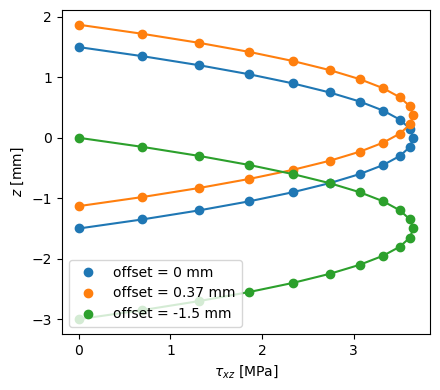

differences divided by the peak 3 Q/(2h)
quantity                                 composites      reference rel. diff.
offset 0: max |tau_xz - parabola|      8.881784e-16   0.000000e+00    2.4e-16
offset 0: max |tau_yz - parabola|      1.110223e-16   0.000000e+00    1.1e-16
offset 0.37: max |tau_xz - parabola|   8.881784e-16   0.000000e+00    2.4e-16
offset 0.37: max |tau_yz - parabola|   1.110223e-16   0.000000e+00    1.1e-16
offset -1.5: max |tau_xz - parabola|   8.881784e-16   0.000000e+00    2.4e-16
offset -1.5: max |tau_yz - parabola|   0.000000e+00   0.000000e+00    0.0e+00


In [4]:
h = 3.
Qx, Qy = 7.3, -2.1
rows = []
fig, ax = plt.subplots(figsize=(4.5, 4))
for offset in [0., +0.37, -1.5]:
    lam = isotropic_plate(thickness=h, E=70e3, nu=0.3, offset=offset)
    zs = np.linspace(-h/2, h/2, 21) + offset
    zbar = zs - offset
    tau = np.array([lam.calc_transverse_shear_stress(z, Qy, Qx) for z in zs])
    parab = 3/(2*h)*(1 - 4*zbar**2/h**2)
    line, = ax.plot(tau[:, 1], zs, 'o', label='offset = %g mm' % offset)
    ax.plot(Qx*parab, zs, '-', color=line.get_color())
    rows.append(('offset %g: max |tau_xz - parabola|' % offset,
                 np.abs(tau[:, 1] - Qx*parab).max(), 0., 3*Qx/(2*h)))
    rows.append(('offset %g: max |tau_yz - parabola|' % offset,
                 np.abs(tau[:, 0] - Qy*parab).max(), 0., 3*abs(Qy)/(2*h)))
ax.set_xlabel(r'$\tau_{xz}$ [MPa]')
ax.set_ylabel('$z$ [mm]')
ax.legend()
fig.tight_layout()
plt.show()
print('differences divided by the peak 3 Q/(2h)')
print_table(rows)

## A posteriori recovery from an FSDT solution

From the strain gradients of an actual FSDT solution,
`Laminate.calc_aposteriori_energy` recovers the stresses by integrating the
equilibrium equations through the thickness and gives their strain energies.
This is the a posteriori approach of Noor and Peters [2], see
[Transverse shear stresses](../transverse_shear_stresses.rst): the recovered
stresses $\bar\tau_{xz}$, $\bar\tau_{yz}$ give the transverse shear strain
energies per unit area of their Eq. (7),

$$
\bar{U}_{13} = \int \frac{1}{2} C_{55} \bar\gamma_{xz}^2 \, dz, \qquad
\bar{U}_{23} = \int \frac{1}{2} C_{44} \bar\gamma_{yz}^2 \, dz,
$$

and equating the FSDT energy $Q_x^2/(2 k_{13} \bar{A}_{55})$ with
$\bar{U}_{13}$ gives the factor $k_{13}$ of their Eq. (8).

For a homogeneous plate in cylindrical bending, $M_{xx} = D
\varepsilon^{(1)}_{xx}$ with $D = E h^3/(12 (1 - \nu^2))$, so $M_{xx,x} = Q_x$
is the curvature gradient $\varepsilon^{(1)}_{xx,x} = Q_x/D$, the entry 3 of
`eps_x` in the order of `ABD`. The references are the resultant $Q_x$, the
energy $\bar{U}_{13} = 3 Q_x^2/(5 G h)$ of the parabola, the factor
$k_{13} = Q_x^2/(2 G h \bar{U}_{13}) = 5/6$ (with $\bar{A}_{55} = G h$), and
$\bar{U}_{23} = 0$.

In [5]:
h, E, nu = 2., 70e3, 0.3
G = E/(2*(1 + nu))
lam = isotropic_plate(thickness=h, E=E, nu=nu)
Qx = 1.7
D = E*h**3/(12*(1 - nu**2))
eps_x = np.zeros(6)
eps_x[3] = Qx/D # M_xx,x = Qx in cylindrical bending
U13, U23, Qy_r, Qx_r = lam.calc_aposteriori_energy(eps_x, np.zeros(6))
print_table([
    ('recovered Qx', Qx_r[0], Qx),
    ('U13 = 3 Qx^2/(5 G h)', U13[0], 0.6*Qx**2/(G*h)),
    ('k13 = Qx^2/(2 G h U13) = 5/6', 0.5*Qx**2/(G*h)/U13[0], 5/6),
    ('U23 = 0 (scale U13)', U23[0], 0., 0.6*Qx**2/(G*h)),
])

quantity                                 composites      reference rel. diff.
recovered Qx                           1.700000e+00   1.700000e+00    2.6e-16
U13 = 3 Qx^2/(5 G h)                   3.220286e-05   3.220286e-05    0.0e+00
k13 = Qx^2/(2 G h U13) = 5/6           8.333333e-01   8.333333e-01    0.0e+00
U23 = 0 (scale U13)                    0.000000e+00   0.000000e+00    0.0e+00


## References

1. Rohwer, K., Improved Transverse Shear Stiffnesses for Layered Finite Elements, DFVLR-FB 88-32, 1988.
2. Noor, A. K. and Peters, J. M., A Posteriori Estimates for the Shear Correction Factors in Multi-layered Composite Cylinders, Journal of Engineering Mechanics, 115(6), 1225-1244, 1989. https://doi.org/10.1061/(asce)0733-9399(1989)115:6(1225)